In [7]:
# unpack the repo
!unzip -q -o /content/multimodal-bird-vision.zip -d /content/project
%cd /content/project
!ls

/content/project
configs  data  notebooks  outputs  README.md  requirements.txt	src


In [ ]:
# download the dataset with the repo’s function
!pip install -q datasets # makes sure Hugging Face’s library is installed
from pathlib import Path
from src.data.download import prepare_cub, load_cub # prepare_cub is M1’s function. It calls load_dataset("Multimodal-Fatima/CUB_train") and CUB_test then saves both to /content/data/cub/train and /content/data/cub/test

DATA_DIR = Path("/content/data")python -m src.cli train --config configs/debug_wandb.yaml
prepare_cub(DATA_DIR)

[prepare-data] train: downloading Multimodal-Fatima/CUB_train ...


README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-ae08e95fea856c(…): reconstructing file:   0%|          |  0.00B /  297MB            

...

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/5794 [00:00<?, ? examples/s]

[prepare-data] test: 5794 records -> /content/data/cub/test


{'train': PosixPath('/content/data/cub/train'),
 'test': PosixPath('/content/data/cub/test')}

Dataset({
    features: ['image', 'description', 'label', 'file_name', 'id'],
    num_rows: 5994
})
Dataset({
    features: ['image', 'description', 'label', 'file_name', 'id'],
    num_rows: 5794
})
number of classes: 200
label: 0 -> Black footed Albatross
file: Black_Footed_Albatross_0007_796138.jpg
image size: (500, 301) mode: RGB
description:
this bird is brown with a lighter brown crest.
aquatic large bird with long hooked bill, white face, and brown body.
bird has brown body feathers, brown breast feathers, and brown beak
this bird has a white superciliary and brown all around its body with a long bill
this is a brown bird with a white face and a long downward pointing beak.
this bird is brown with white and has a long, pointy beak.
brown duck playing on the lake making a poodle
this bird has wings that are brown and has a long bill
this bird has long brown bill, with a brown body.
this is a medium sized brown bird, with a long pointed bill.



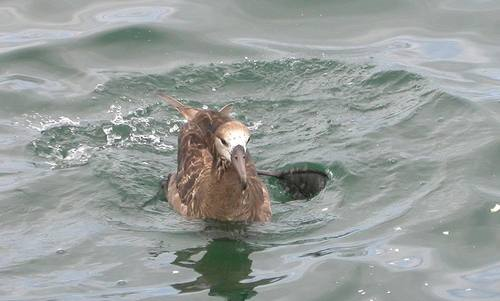

In [9]:
train = load_cub(DATA_DIR, "train")
test = load_cub(DATA_DIR, "test")
print(train)
print(test)

names = train.features["label"].names
print("number of classes:", len(names))

ex = train[0]
print("label:", ex["label"], "->", names[ex["label"]])
print("file:", ex["file_name"])
print("image size:", ex["image"].size, "mode:", ex["image"].mode)
print("description:\n" + ex["description"])
ex["image"]

train: min 29, max 30, mean 30.0, std 0.2
   fewest images: [('Common Raven', 29), ('Nelson Sharp tailed Sparrow', 29), ('Artic Tern', 29), ('Bank Swallow', 29), ('House Wren', 29)]
test: min 11, max 30, mean 29.0, std 2.9
   fewest images: [('Least Auklet', 11), ('Crested Auklet', 14), ('Spotted Catbird', 15), ('Rhinoceros Auklet', 18), ('Whip poor Will', 19)]


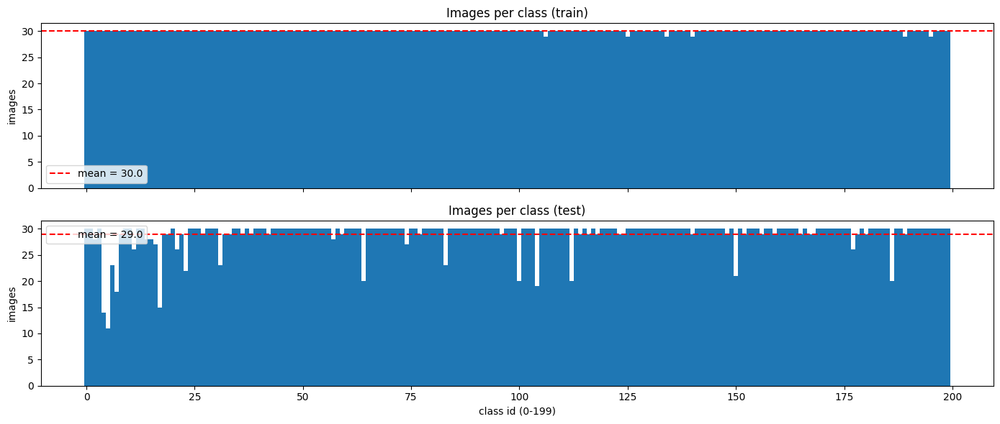

In [10]:
import numpy as np
import matplotlib.pyplot as plt

train_labels = np.array(train["label"])
test_labels = np.array(test["label"])

train_counts = np.bincount(train_labels, minlength=200)
test_counts = np.bincount(test_labels, minlength=200)

for split_name, counts in [("train", train_counts), ("test", test_counts)]:
    print(f"{split_name}: min {counts.min()}, max {counts.max()}, "
          f"mean {counts.mean():.1f}, std {counts.std():.1f}")
    fewest = np.argsort(counts)[:5]
    print("   fewest images:", [(names[i], int(counts[i])) for i in fewest])

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, split_name, counts in [(axes[0], "train", train_counts), (axes[1], "test", test_counts)]:
    ax.bar(range(200), counts, width=1.0)
    ax.axhline(counts.mean(), color="red", linestyle="--", label=f"mean = {counts.mean():.1f}")
    ax.set_ylabel("images")
    ax.set_title(f"Images per class ({split_name})")
    ax.legend()
axes[1].set_xlabel("class id (0-199)")
plt.tight_layout()
plt.show()

--- train: 5994 images
     width  height  aspect
min  121.0   120.0    0.49
25%  492.0   333.0    1.07
50%  500.0   375.0    1.33
75%  500.0   435.0    1.50
max  500.0   500.0    3.60
color modes: {'RGB': 5990, 'L': 4}
short side < 224 px: 74

--- test: 5794 images
     width  height  aspect
min  140.0  134.00    0.38
25%  498.0  333.00    1.09
50%  500.0  375.00    1.33
75%  500.0  432.75    1.50
max  500.0  500.00    2.56
color modes: {'RGB': 5790, 'L': 4}
short side < 224 px: 74



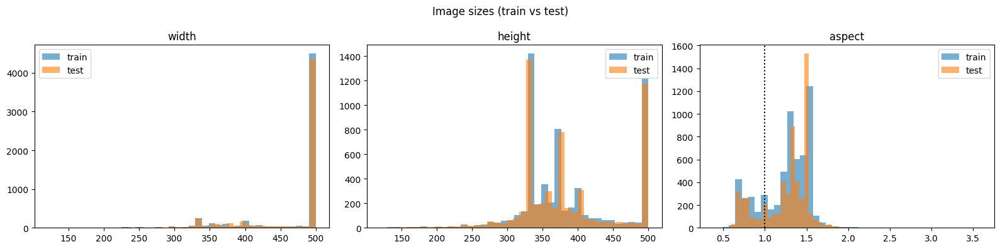

In [11]:
# check image sizes and color modes
import io
import pandas as pd
from PIL import Image as PILImage
from datasets import Image as HFImage

def image_info(ds):
    """Width, height and color mode of every image, without decoding the pixels."""
    raw = ds.cast_column("image", HFImage(decode=False))
    rows = []
    for rec in raw["image"]:
        with PILImage.open(io.BytesIO(rec["bytes"])) as img:
            rows.append((img.width, img.height, img.mode))
    return pd.DataFrame(rows, columns=["width", "height", "mode"])

info = {}
for split_name, ds in [("train", train), ("test", test)]:
    df = image_info(ds)
    df["aspect"] = df["width"] / df["height"]
    df["short_side"] = df[["width", "height"]].min(axis=1)
    info[split_name] = df

    print(f"--- {split_name}: {len(df)} images")
    print(df[["width", "height", "aspect"]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(2))
    print("color modes:", df["mode"].value_counts().to_dict())
    print("short side < 224 px:", int((df["short_side"] < 224).sum()))
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for col, ax in zip(["width", "height", "aspect"], axes):
    for split_name, df in info.items():
        ax.hist(df[col], bins=40, alpha=0.6, label=split_name)
    ax.set_title(col)
    ax.legend()
axes[2].axvline(1.0, color="black", linestyle=":", label="square")
plt.suptitle("Image sizes (train vs test)")
plt.tight_layout()
plt.show()

In [12]:
# recording each image’s mode (for filtering later)
import os
os.makedirs("outputs/eda", exist_ok=True)

for split_name, ds, labels in [("train", train, train_labels), ("test", test, test_labels)]:
    df = info[split_name]
    df["file_name"] = list(ds["file_name"])
    df["label"] = labels
    df.to_csv(f"outputs/eda/image_info_{split_name}.csv", index_label="index")

    print(f"{split_name}: non-RGB images")
    print(df.loc[df["mode"] != "RGB", ["file_name", "mode", "width", "height"]], "\n")

train: non-RGB images
                             file_name mode  width  height
726   Pelagic_Cormorant_0022_23802.jpg    L    500     375
1868         Ivory_Gull_0040_49180.jpg    L    500     326
1950       Western_Gull_0002_54825.jpg    L    500     281
2764   Clark_Nutcracker_0020_85099.jpg    L    500     500 

test: non-RGB images
                               file_name mode  width  height
193       Brewer_Blackbird_0028_2682.jpg    L    500     333
1764           Ivory_Gull_0085_49456.jpg    L    500     398
2472              Mallard_0130_76836.jpg    L    485     500
3082  White_Necked_Raven_0070_102645.jpg    L    484     500 



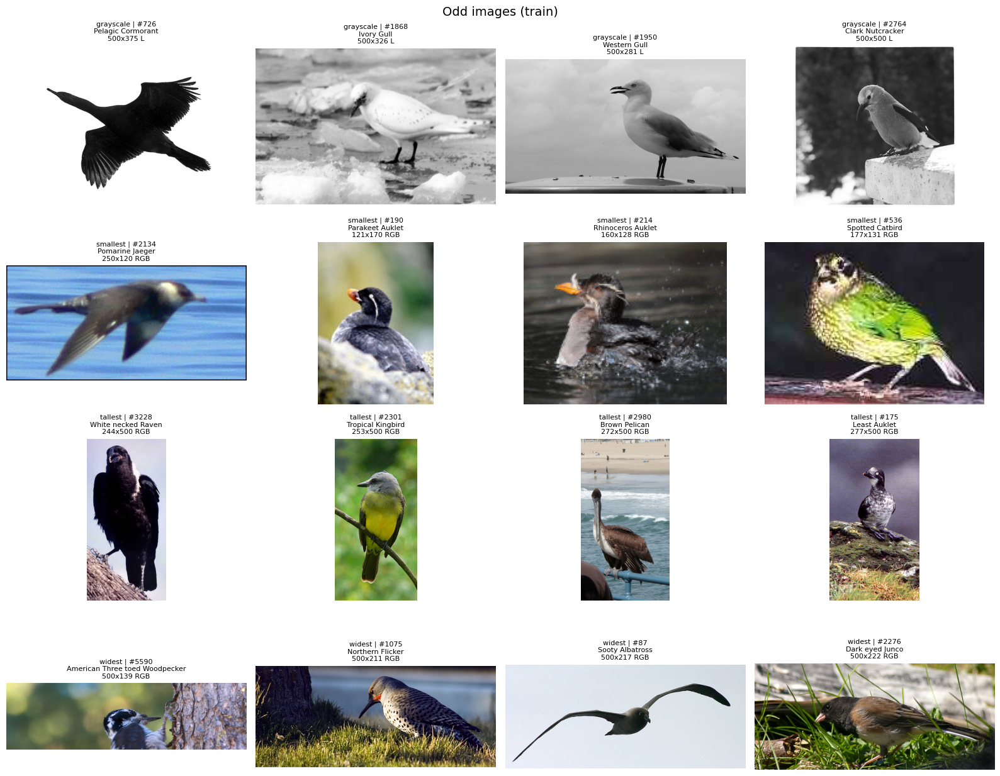

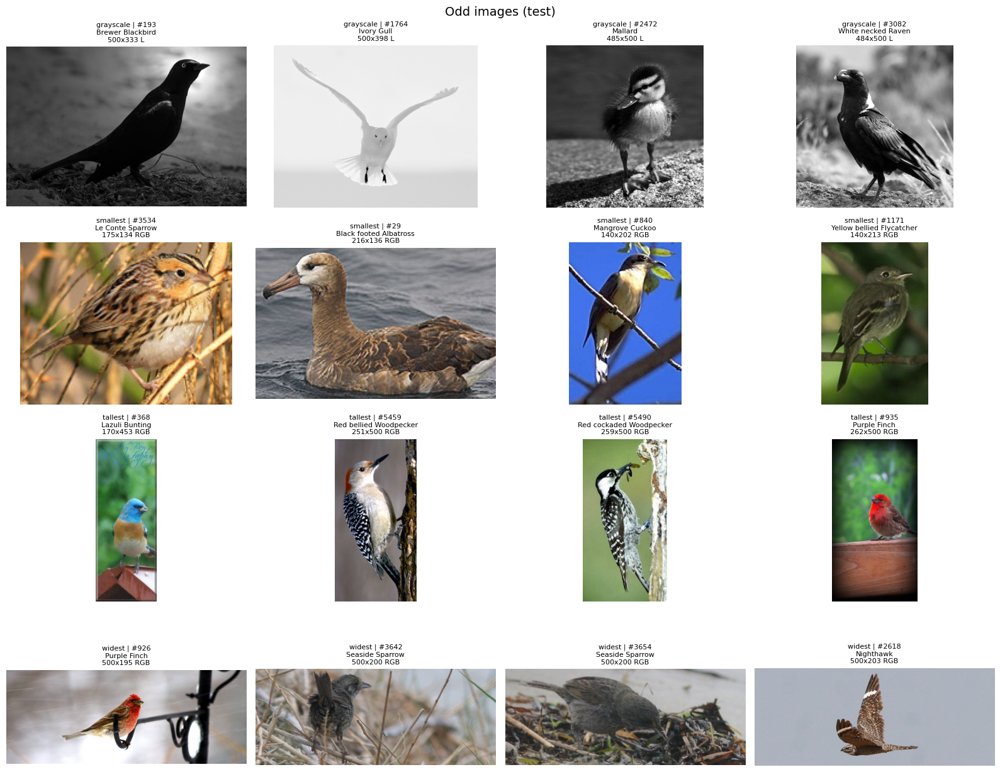

In [13]:
# Inspection of the extremes (grayscale, smallest, tallest, widest)
def show_odd_images(ds, df, labels, split_name):
    groups = [
        ("grayscale", df.index[df["mode"] != "RGB"][:4]),
        ("smallest",  df.nsmallest(4, "short_side").index),
        ("tallest",   df.nsmallest(4, "aspect").index),
        ("widest",    df.nlargest(4, "aspect").index),
    ]
    fig, axes = plt.subplots(len(groups), 4, figsize=(16, 13))
    for row, (group_name, indices) in enumerate(groups):
        for col in range(4):
            ax = axes[row, col]
            ax.axis("off")
            if col >= len(indices):
                continue
            i = int(indices[col])
            img = ds[i]["image"]
            ax.imshow(img, cmap="gray" if img.mode == "L" else None)
            ax.set_title(f"{group_name} | #{i}\n{names[labels[i]]}\n{img.width}x{img.height} {img.mode}",
                         fontsize=8)
    plt.suptitle(f"Odd images ({split_name})", fontsize=14)
    plt.tight_layout()
    plt.show()

show_odd_images(train, info["train"], train_labels, "train")
show_odd_images(test, info["test"], test_labels, "test")

In [15]:
# fingerprint every image
!pip install -q imagehash
import imagehash, time

def compute_phashes(ds):
    raw = ds.cast_column("image", HFImage(decode=False))
    hashes = []
    for rec in raw["image"]:
        with PILImage.open(io.BytesIO(rec["bytes"])) as img:
            hashes.append(imagehash.phash(img))
    return hashes

t0 = time.time()
train_hashes = compute_phashes(train)
test_hashes = compute_phashes(test)
print(f"{len(train_hashes)} train + {len(test_hashes)} test hashes in {time.time() - t0:.0f}s")
print("example hash:", train_hashes[0], "(64 bits written as 16 hex digits)")

5994 train + 5794 test hashes in 32s
example hash: b38cc374c9d36263 (64 bits written as 16 hex digits)


In [34]:
# Comparing every image with every other image
THRESHOLD = 5   # max differing bits (out of 64) to call two images near-duplicates

bits = np.array([h.hash.flatten() for h in train_hashes + test_hashes])   # (11788, 64) True/False
all_labels = np.concatenate([train_labels, test_labels])
n_train = len(train_hashes)

def where(n):
    """Position in the combined list -> (split, index inside that split)."""
    return ("train", n) if n < n_train else ("test", n - n_train)

pairs = []
for i in range(len(bits)):
    dist = (bits[i] != bits[i + 1:]).sum(axis=1)       # differing bits vs every later image
    for k in np.nonzero(dist <= THRESHOLD)[0]:
        pairs.append((i, i + 1 + k, int(dist[k])))


# ---- save the pairs as a table ----
rows = []
for i, j, d in pairs:
    (split_a, index_a), (split_b, index_b) = where(i), where(j)
    rows.append({
        "split_a": split_a, "index_a": index_a, "label_a": names[all_labels[i]],
        "split_b": split_b, "index_b": index_b, "label_b": names[all_labels[j]],
        "distance": d,
    })

dups = pd.DataFrame(rows, columns=["split_a", "index_a", "label_a", "split_b", "index_b", "label_b", "distance"])
dups["kind"] = dups["split_a"] + "-" + dups["split_b"]
dups["same_label"] = dups["label_a"] == dups["label_b"]
dups = dups.sort_values("distance").reset_index(drop=True)
dups.to_csv("outputs/eda/duplicates.csv", index=False)

print("\nby kind:", dups["kind"].value_counts().to_dict())
print("pairs with different labels:", int((~dups["same_label"]).sum()))
dups


by kind: {'test-test': 6, 'train-test': 5, 'train-train': 3}
pairs with different labels: 5


,split_a,index_a,label_a,split_b,index_b,label_b,distance,kind,same_label
0,train,774,Bronzed Cowbird,test,661,Bronzed Cowbird,0,train-test,True
1,train,1712,Pigeon Guillemot,train,1731,Pigeon Guillemot,0,train-train,True
2,train,5315,Swainson Warbler,train,5333,Swainson Warbler,0,train-train,True
3,test,565,Chuck will Widow,test,2974,Whip poor Will,0,test-test,False
4,test,2368,Red legged Kittiwake,test,2374,Red legged Kittiwake,0,test-test,True
5,test,4004,Summer Tanager,test,4026,Summer Tanager,0,test-test,True
6,test,3264,Brewer Sparrow,test,3276,Brewer Sparrow,2,test-test,True
7,train,5277,Prothonotary Warbler,test,5115,Prothonotary Warbler,2,train-test,True
8,train,2529,Horned Lark,test,4115,Caspian Tern,4,train-test,False
9,train,46,Laysan Albatross,train,57,Laysan Albatross,4,train-train,True


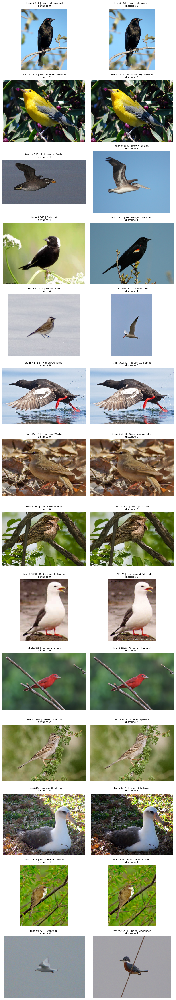

In [35]:
ds_by_split = {"train": train, "test": test}
cross_split_first = sorted(pairs, key=lambda p: (where(p[0])[0] == where(p[1])[0], p[2]))
show = cross_split_first[:]

if not show:
    print("No near-duplicate pairs found.")
else:
    fig, axes = plt.subplots(len(show), 2, figsize=(8, 3.2 * len(show)), squeeze=False)
    for row, (i, j, d) in enumerate(show):
        for col, n in enumerate([i, j]):
            split_name, idx = where(n)
            img = ds_by_split[split_name][idx]["image"]
            axes[row, col].imshow(img, cmap="gray" if img.mode == "L" else None)
            axes[row, col].set_title(f"{split_name} #{idx} | {names[all_labels[n]]}\ndistance {d}", fontsize=8)
            axes[row, col].axis("off")
    plt.tight_layout()
    plt.show()

In [36]:
# saving the exclude list
exclude_train = {
    774:  "duplicate of test #661 (train-test leakage)",
    5277: "duplicate of test #5115 (train-test leakage)",
    1731: "duplicate of train #1712",
    5333: "duplicate of train #5315",
    57:   "duplicate of train #46",
}

train_files = list(train["file_name"])
exclude = pd.DataFrame([
    {"split": "train", "file_name": train_files[i], "reason": reason}
    for i, reason in exclude_train.items()
])
exclude.to_csv("outputs/eda/exclude.csv", index=False)

print(f"excluded {len(exclude)} train images -> {len(train) - len(exclude)} remain")
exclude

excluded 5 train images -> 5989 remain


,split,file_name,reason
0,train,Bronzed_Cowbird_0074_24045.jpg,duplicate of test #661 (train-test leakage)
1,train,Prothonotary_Warbler_0020_174122.jpg,duplicate of test #5115 (train-test leakage)
2,train,Pigeon_Guillemot_0081_40339.jpg,duplicate of train #1712
3,train,Swainson_Warbler_0049_794880.jpg,duplicate of train #5315
4,train,Laysan_Albatross_0096_673.jpg,duplicate of train #46


In [37]:
# The validation split
import json
from sklearn.model_selection import train_test_split

SEED = 42
VAL_FRACTION = 0.1

# 1) drop the excluded images first
excluded = set(exclude["file_name"])
keep = [i for i, f in enumerate(train_files) if f not in excluded]
keep_labels = train_labels[keep]

# 2) stratified split of what is left
train_idx, val_idx = train_test_split(keep, test_size=VAL_FRACTION,
                                      stratify=keep_labels, random_state=SEED)

# 3) checks
assert not set(train_idx) & set(val_idx), "an image is in both train and val"
assert len(train_idx) + len(val_idx) == len(keep), "A lost image"
assert not excluded & {train_files[i] for i in train_idx + val_idx}, "an excluded image slipped in"
train_per_class = np.bincount(train_labels[train_idx], minlength=200)
val_per_class = np.bincount(train_labels[val_idx], minlength=200)
assert train_per_class.min() > 0 and val_per_class.min() > 0, "a species is missing from a split"

print(f"kept {len(keep)} | train {len(train_idx)} | val {len(val_idx)}")
print(f"train per species: min {train_per_class.min()}, max {train_per_class.max()}")
print(f"val per species:   min {val_per_class.min()}, max {val_per_class.max()}")

# 4) save by file name, with the settings used
split = {
    "seed": SEED,
    "val_fraction": VAL_FRACTION,
    "stratified_by": "label",
    "excluded_first": "exclude.csv",
    "train": sorted(train_files[i] for i in train_idx),
    "val": sorted(train_files[i] for i in val_idx),
}
with open("outputs/eda/split_seed42.json", "w") as f:
    json.dump(split, f, indent=1)
print("saved outputs/eda/split_seed42.json")

kept 5989 | train 5390 | val 599
train per species: min 26, max 27
val per species:   min 2, max 3
saved outputs/eda/split_seed42.json


In [38]:
# mean/std on the final train split only
import torch
from torchvision import transforms as T

prep = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor()])

total = torch.zeros(3, dtype=torch.float64)
total_sq = torch.zeros(3, dtype=torch.float64)
n_pixels = 0

t0 = time.time()
for i in train_idx:
    x = prep(train[int(i)]["image"].convert("RGB")).double()   # (3, 224, 224), values 0..1
    total += x.sum(dim=(1, 2))
    total_sq += (x ** 2).sum(dim=(1, 2))
    n_pixels += x.shape[1] * x.shape[2]

mean = total / n_pixels
std = (total_sq / n_pixels - mean ** 2).sqrt()
print(f"computed on {len(train_idx)} train images in {time.time() - t0:.0f}s")
print("CUB train mean:", [round(v, 4) for v in mean.tolist()])
print("CUB train std: ", [round(v, 4) for v in std.tolist()])
print("ImageNet mean:  [0.485, 0.456, 0.406]   std: [0.229, 0.224, 0.225]")

with open("outputs/eda/channel_stats.json", "w") as f:
    json.dump({"mean": [round(v, 4) for v in mean.tolist()], "std": [round(v, 4) for v in std.tolist()],
               "computed_on": "train split (val and test excluded), resize 256 + center crop 224",
               "split_file": "split_seed42.json"}, f, indent=1)

computed on 5390 train images in 22s
CUB train mean: [0.4825, 0.4913, 0.4249]
CUB train std:  [0.228, 0.2239, 0.2591]
ImageNet mean:  [0.485, 0.456, 0.406]   std: [0.229, 0.224, 0.225]
